---
## Task 4 - Trend Analysis by Release Year
---

### Organizing content by release year

In [1]:
# Loading the dataset
import pandas as pd
df = pd.read_csv('cleaned_dataset.csv')

In [2]:
#Sorting the original dataset by release year(oldest to newest)
df_sorted = df.sort_values(by='release_year', ascending=True)

#Displaying the sorted dataset
df_sorted.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
421,s4251,Tv Show,Pioneers: First Women Filmmakers*,NaN,Pakistan,2018-12-30,1925,TV-14,1 Season,TV Shows,1,Season
6037,s8206,Movie,The Battle of Midway,John Ford,United States,2017-03-31,1942,TV-14,18 min,"Classic Movies, Documentaries",18,min
5698,s7791,Movie,Prelude to War,Frank Capra,United States,2017-03-31,1942,TV-14,52 min,"Classic Movies, Documentaries",52,min
6422,s8661,Movie,Undercover: How to Operate Behind Enemy Lines,John Ford,United States,2017-03-31,1943,TV-PG,61 min,"Classic Movies, Documentaries",61,min
6510,s8764,Movie,WWII: Report from the Aleutians,John Huston,United States,2017-03-31,1943,TV-PG,45 min,Documentaries,45,min


### Calculating yearly content releases

In [3]:
#Caluclating how many titles were released each year
yearly_counts = df_sorted['release_year'].value_counts().sort_index()

#Converting to DataFrame for easier inspection
df_yearly = pd.DataFrame({
    'Release_year': yearly_counts.index,
    'Title_counts': yearly_counts.values
})

#Displaying recent release years(Last 15 years)
df_yearly.tail(15)

,Release_year,Title_counts
59,2007,88
60,2008,135
61,2009,152
62,2010,192
63,2011,185
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901


In [4]:
#Grouping by release year and type to get counts for both Movies and TV Shows
type_yearly = df_sorted.groupby(['release_year', 'type'], observed=False).size().unstack(fill_value=0)

#Displaying most recent 15 release years
type_yearly.tail(15)

type,Movie,Tv Show
release_year,,
2007,74,14
2008,113,22
2009,118,34
2010,153,39
2011,145,40
2012,173,63
2013,225,61
2014,264,88
2015,396,159


### Identifying growth and decline trends

In [5]:
#Filtering and calculating total releases per year from 2000 onwards
total_yearly = df[df['release_year'] >= 2000]['release_year'].value_counts().sort_index()

#Getting peak release year and its corresponding count
peak_year = total_yearly.idxmax()
peak_count = total_yearly.max()

#Printing the results
print(f"Peak Content Release Year: {peak_year} ({peak_count} titles)")
print("\nRecent 5-Year Content Volume Summary:")
print(total_yearly.tail(5))

Peak Content Release Year: 2018 (1146 titles)

Recent 5-Year Content Volume Summary:
release_year
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


### Creating Trend Visualizations

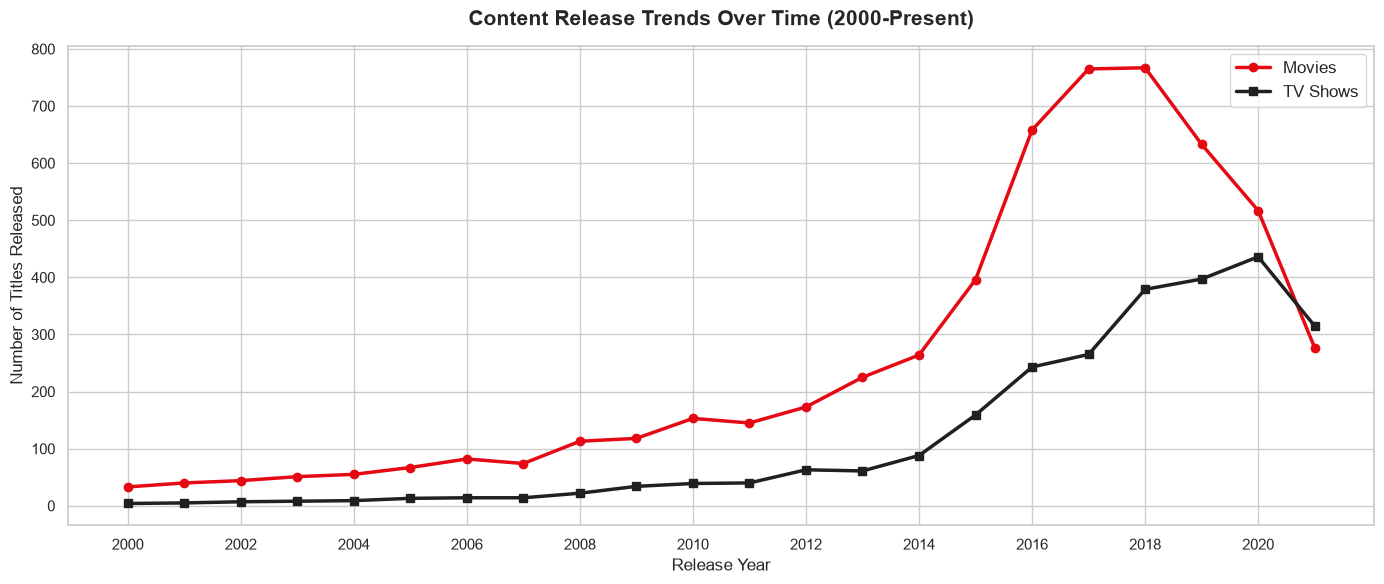

In [6]:
#Importing visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#Grouping by release_year and type for modern era (2000-Present)
type_yearly_modern = df[df['release_year'] >= 2000].groupby(['release_year', 'type'], observed=False).size().unstack(fill_value=0)

#Setting figure and size
plt.figure(figsize=(14,6))
sns.set_theme(style='whitegrid')

#Plotting line charts for Movies and TV Shows
plt.plot(type_yearly_modern.index, type_yearly_modern['Movie'], marker='o', color='#E50914', linewidth=2.5, label='Movies')
plt.plot(type_yearly_modern.index, type_yearly_modern['Tv Show'], marker='s', color='#221F1F', linewidth=2.5, label='TV Shows')

#Titles and Labels
plt.title('Content Release Trends Over Time (2000-Present)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles Released', fontsize=12)
plt.xticks(range(2000, type_yearly_modern.index.max() + 1,2))
plt.legend(fontsize=12)

#Displaying plot
plt.tight_layout()
plt.show()

### Business Patterns


1. **The Aggressive Library Expansion Era(2015-2018):**


*   Annual release additions experienced exponential growth, climbing from **555 titles in 2015** to an all-time peak of **1,146 titles in 2018**.
*   The rapid surge aligns directly with Netflix's global platform rollout and massive financial pivot toward commissioning Netflix Originals alongside aggressive third-party studio licensing.


2.   **Film Peak vs. TV Series Momentum**


*   Movies Peaked in **2018(767 titles)** before experiencing a steady decline in annual release conditions.
*   TV Shows sustained strong growth momentum through **2020(436 titles)**, overtaking movie additions in relative trajectory. This highlights Netflix's strategic pivot toward high-retention, multi-episode series that drive ongoing subscriber engagement and lower monthly churn.

3. **Post-2020 Market Adjustments & Data Realities**:
** Releases dropped sharply in **2021(592 titles)**. This decline reflects two primary factors:
  
  **Production Disruptions**: Global filming delays caused by the 2020 COVID-19 pandemic directly impacted release schedules in 2020-2021.

  **Licensing Dynamics**: Standard catalog licensing expiration cycles and the widthdrawal of third-party studio titles as rival media companies launched dedicated streaming services.




### Strategic Recommendations for Business Leadership

1. **Balance Portfolio Allocation**: Continue prioritizing episodic original TV series for subscriber retention while maintaining a curated, high-quality movie acquisition strategy to drive new subscriber sign-ups.

2. **Diverisfy Production Hubs**: Expand investments in regional production hubs (particularly across Asia, Latin America and Sub-Saharan Africa) to hedge against localized production bottlenecks and licensing expirations in mature Western markets.